## Парсинг Гисметео

Сейчас на дворе осень 2026 года, но я не могу отделаться от мысли, как бы мне хотелось поваляться на солнышке в свой отпуск. Вот я и решил распарсить Гисметео и выбрать лучшие недели для своего отдыха.

Возможно, набор локаций покажется вам странным, но не удивляйтесь. Моя прабабушка хотела побывать именно в этих местах...

Так как гисметео не защищен никакими сложными блокираторами парсинга, здесь напрямую можно использовать requests и BeautifulSoup.

Как устроен код:

1. Для каждого города открываем на Гисметео страницу с прогнозом на месяц.
2. Из каждой клетки календаря достаем дату, дневную и ночную температуру и описание погоды.
3. Каждому дню ставим штраф за осадки и за слишком жаркую или холодную погоду.
4. Складываем штрафы по неделям и смотрим, где и когда погода лучше всего.

У каждого города на Гисметео свой адрес, например `gismeteo.ru/weather-madrid-1950/month/`. Хвост `madrid-1950` - это название города и его номер на сайте. Угадать этот номер нельзя, поэтому для каждого города я нашел его руками и записал в список ниже.

In [1]:
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

In [2]:
destinations = [
    {'country': 'Испания', 'city': 'Мадрид', 'gismeteo_suffix': 'madrid-1950'},
    {'country': 'Испания', 'city': 'Барселона', 'gismeteo_suffix': 'barcelona-1948'},
    {'country': 'Испания', 'city': 'Тенерифе', 'gismeteo_suffix': 'santa-cruz-de-tenerife-6468'},
    {'country': 'Италия', 'city': 'Рим', 'gismeteo_suffix': 'rome-3561'},
    {'country': 'Италия', 'city': 'Римини', 'gismeteo_suffix': 'rimini-3534'},
    {'country': 'Греция', 'city': 'Афины', 'gismeteo_suffix': 'athens-3673'},

    {'country': 'Турция', 'city': 'Анталья', 'gismeteo_suffix': 'antalya-3787'},
    {'country': 'Турция', 'city': 'Стамбул', 'gismeteo_suffix': 'istanbul-3719'},
    {'country': 'Египет', 'city': 'Шарм-эш-Шейх', 'gismeteo_suffix': 'sharm-el-sheikh-6617'},
    {'country': 'Египет', 'city': 'Хургада', 'gismeteo_suffix': 'hurghada-6618'},
    {'country': 'ОАЭ', 'city': 'Дубай', 'gismeteo_suffix': 'dubai-5529'},

    {'country': 'Таиланд', 'city': 'Пхукет', 'gismeteo_suffix': 'phuket-6002'},
    {'country': 'Таиланд', 'city': 'Бангкок', 'gismeteo_suffix': 'bangkok-5993'},
    {'country': 'Вьетнам', 'city': 'Нячанг', 'gismeteo_suffix': 'nha-trang-6040'},
    {'country': 'Индонезия', 'city': 'Бали', 'gismeteo_suffix': 'denpasar-10859'},
    {'country': 'Шри-Ланка', 'city': 'Коломбо', 'gismeteo_suffix': 'colombo-5800'},

    {'country': 'Франция', 'city': 'Париж', 'gismeteo_suffix': 'paris-1623'},
    {'country': 'Франция', 'city': 'Ницца', 'gismeteo_suffix': 'nice-1892'},
    {'country': 'Чехия', 'city': 'Прага', 'gismeteo_suffix': 'prague-2952'},
    {'country': 'Нидерланды', 'city': 'Амстердам', 'gismeteo_suffix': 'amsterdam-1200'},

    {'country': 'Грузия', 'city': 'Батуми', 'gismeteo_suffix': 'batumi-5275'},
    {'country': 'Армения', 'city': 'Ереван', 'gismeteo_suffix': 'yerevan-5298'}
]


In [3]:
HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/114.0.0.0 Safari/537.36'}

all_data = []

for dest in destinations:
    url = f"https://www.gismeteo.ru/weather-{dest['gismeteo_suffix']}/month/"
    print(f"данные: {dest['city']}")
    
    response = requests.get(url, headers=HEADERS, timeout=10)
    soup = BeautifulSoup(response.text, 'html.parser')
    
    squares = soup.select('.row-item-month-date')
    
    cur_month = ""
    
    for el in squares:
        date_tag = el.select_one('.date')
        maxt_tag = el.select_one('.maxt temperature-value')
        mint_tag = el.select_one('.mint temperature-value')
        weather = el.get('data-tooltip', '').strip()
        
        if date_tag and maxt_tag and mint_tag:
            raw_date = date_tag.get_text(strip=True)
            parts = raw_date.split()
            day = parts[0]
            
            if len(parts) > 1:
                cur_month = parts[1]
            clean_date = f"{day} {cur_month}"
            
            all_data.append({
                'country': dest['country'],
                'city': dest['city'],
                'date': clean_date,
                'weather': weather,
                'maxt': int(maxt_tag.get('value')),
                'mint': int(mint_tag.get('value'))
            })


df = pd.DataFrame(all_data)

print(df.head(100))

данные: Мадрид


данные: Барселона


данные: Тенерифе


данные: Рим


данные: Римини


...

данные: Прага


данные: Амстердам


данные: Батуми


данные: Ереван


    country      city     date                                weather  maxt  \
0   Испания    Мадрид   12 окт                             безоблачно    28   
1   Испания    Мадрид   13 окт                             безоблачно    28   
2   Испания    Мадрид   14 окт                             безоблачно    29   
3   Испания    Мадрид   15 окт                             безоблачно    28   
4   Испания    Мадрид   16 окт  малооблачно, без существенных осадков    26   
..      ...       ...      ...                                    ...   ...   
95  Испания  Тенерифе   6 нояб               облачно, небольшой дождь    21   
96  Испания  Тенерифе   7 нояб               облачно, небольшой дождь    21   
97  Испания  Тенерифе   8 нояб              пасмурно, небольшой дождь    21   
98  Испания  Тенерифе   9 нояб                                облачно    20   
99  Испания  Тенерифе  10 нояб           малооблачно, небольшой дождь    20   

    mint  
0     12  
1     14  
2     17  
3     1

In [4]:
from datetime import datetime

month_map = {
    'янв': 1, 'фев': 2, 'мар': 3, 'апр': 4,
    'май': 5, 'июн': 6, 'июл': 7,
    'авг': 8, 'сен': 9, 'окт': 10, 'ноя': 11, 'дек': 12
}

df[['day', 'month_text']] = df['date'].str.split(expand=True)

df['month'] = df['month_text'].str[:3].map(month_map)
df['day'] = df['day'].astype(int)

cur_year = datetime.now().year
cur_month = datetime.now().month

df['year'] = cur_year
df.loc[(cur_month == 12) & (df['month'] == 1), 'year'] = cur_year + 1

df['date'] = pd.to_datetime(df[['year', 'month', 'day']])

df = df.drop(columns=['day', 'month_text', 'month', 'year'])
df['collected_at'] = pd.Timestamp.today().normalize()
df.head()

,country,city,date,weather,maxt,mint,collected_at
0,Испания,Мадрид,2026-10-12,безоблачно,28,12,2026-10-13
1,Испания,Мадрид,2026-10-13,безоблачно,28,14,2026-10-13
2,Испания,Мадрид,2026-10-14,безоблачно,29,17,2026-10-13
3,Испания,Мадрид,2026-10-15,безоблачно,28,16,2026-10-13
4,Испания,Мадрид,2026-10-16,"малооблачно, без существенных осадков",26,15,2026-10-13


In [5]:
DATA_FILE = "gismeteo_forecast.csv"
df.to_csv(DATA_FILE, index=False)

In [6]:
df = pd.read_csv(DATA_FILE, parse_dates=['date', 'collected_at'])

collected_at = df['collected_at'].max()
print(f"Данные собраны {collected_at:%d.%m.%Y}, прогноз с {df['date'].min():%d.%m.%Y} по {df['date'].max():%d.%m.%Y}")

Данные собраны 13.10.2026, прогноз с 12.10.2026 по 15.11.2026


In [7]:
df.head()

,country,city,date,weather,maxt,mint,collected_at
0,Испания,Мадрид,2026-10-12,безоблачно,28,12,2026-10-13
1,Испания,Мадрид,2026-10-13,безоблачно,28,14,2026-10-13
2,Испания,Мадрид,2026-10-14,безоблачно,29,17,2026-10-13
3,Испания,Мадрид,2026-10-15,безоблачно,28,16,2026-10-13
4,Испания,Мадрид,2026-10-16,"малооблачно, без существенных осадков",26,15,2026-10-13


### Найдем уникальные погодные события, чтобы в дальнейшем присвоить каждому из них свои веса.

In [8]:
events = df['weather'].apply(lambda x : x.split(', ')).explode().unique()
events

<StringArray>
[              'безоблачно',              'малооблачно',
 'без существенных осадков',                    'дождь',
                    'гроза',                  'облачно',
          'небольшой дождь',                 'пасмурно',
            'сильный дождь',                    'туман',
      'очень сильный дождь',                     'град',
           'ливневый дождь',         'небольшая морось']
Length: 14, dtype: str

### Мы хотим как-то ранжировать погоду между собой. 
Универсального и правильного варианта расстановки весов просто не существует, потому что это очень субъективно. 

Например, моя прабабушка любила солнечную погоду, и даже небольшой дождь ее расстраивал, мы сделаем любую дождливую погоду с весом 40, а любую не-дождливую с весом 0

```python
weather_dic = {
    'безоблачно' : 0,
    'малооблачно' : 0,
    'облачно' : 0,
    'пасмурно' : 0,
    'небольшой дождь' : 40,
    'дождь' : 40,
    'сильный дождь' : 40,
    'без существенных осадков' : 0,
    'гроза' : 40,
    'очень сильный дождь' : 40,
    'град' : 40,
    'туман' : 0,
    'ливневый дождь' : 40
}
```

Но если бы я выбирал погоду под себя, я бы сделал так:

```python
weather_dic = {
    'безоблачно' : 0,
    'малооблачно' : 1,
    'облачно' : 3,
    'пасмурно' : 5,
    'небольшой дождь' : 10,
    'дождь' : 20,
    'сильный дождь' : 40,
    'без существенных осадков' : 3,
    'гроза' : 15,
    'очень сильный дождь' : 50,
    'град' : 40,
    'туман' : 15,
    'ливневый дождь' : 40
}
```

Честно говоря, сильный дождь, по моему мнению, в разы хуже, чем обычный дождь. А очень сильный дождь не очень-то и отличается от просто сильного. А вот грозу я люблю, она получше обычного дождя.

Дальше продолжим работать с моим вариантом

In [4]:
weather_dic = {
    'безоблачно' : 0,
    'малооблачно' : 1,
    'облачно' : 3,
    'пасмурно' : 5,
    'небольшой дождь' : 10,
    'дождь' : 20,
    'сильный дождь' : 40,
    'без существенных осадков' : 3,
    'гроза' : 15,
    'очень сильный дождь' : 50,
    'град' : 40,
    'туман' : 15,
    'ливневый дождь' : 40,
    'небольшая морось' : 5
}

In [10]:
df['weather_rate'] = df['weather'].apply(
    lambda x: sum(weather_dic.get(event.strip(), 0) for event in x.split(','))
)

In [11]:
df.head(100)

,country,city,date,weather,maxt,mint,collected_at,weather_rate
0,Испания,Мадрид,2026-10-12,безоблачно,28,12,2026-10-13,0
1,Испания,Мадрид,2026-10-13,безоблачно,28,14,2026-10-13,0
2,Испания,Мадрид,2026-10-14,безоблачно,29,17,2026-10-13,0
3,Испания,Мадрид,2026-10-15,безоблачно,28,16,2026-10-13,0
4,Испания,Мадрид,2026-10-16,"малооблачно, без существенных осадков",26,15,2026-10-13,4
...,...,...,...,...,...,...,...,...
95,Испания,Тенерифе,2026-11-06,"облачно, небольшой дождь",21,19,2026-10-13,13
96,Испания,Тенерифе,2026-11-07,"облачно, небольшой дождь",21,20,2026-10-13,13
97,Испания,Тенерифе,2026-11-08,"пасмурно, небольшой дождь",21,19,2026-10-13,15
98,Испания,Тенерифе,2026-11-09,облачно,20,19,2026-10-13,3


### Проведем оценку температуры в течение дня. Будем штрафовать за слишком высокие и низкие температуры

Комфортной считаю дневную температуру от 24 до 31 градуса. За каждый градус выше штраф 2, за каждый градус ниже - 4. Холод штрафую сильнее. В жару можно уйти в тень или в воду, а когда на пляже холодно это грустно и с этим ничего не сделаешь.

In [12]:
def temp_rate(t_max):
    rate = 0 
    if t_max > 31:
        rate += (t_max - 31) * 2
    elif t_max < 24:
        rate += (24 - t_max) * 4
    return rate
    
df['temp_rate'] = df['maxt'].apply(temp_rate)
df['sum_rate'] = df['temp_rate'] + df['weather_rate']

In [13]:
df.head()

,country,city,date,weather,maxt,mint,collected_at,weather_rate,temp_rate,sum_rate
0,Испания,Мадрид,2026-10-12,безоблачно,28,12,2026-10-13,0,0,0
1,Испания,Мадрид,2026-10-13,безоблачно,28,14,2026-10-13,0,0,0
2,Испания,Мадрид,2026-10-14,безоблачно,29,17,2026-10-13,0,0,0
3,Испания,Мадрид,2026-10-15,безоблачно,28,16,2026-10-13,0,0,0
4,Испания,Мадрид,2026-10-16,"малооблачно, без существенных осадков",26,15,2026-10-13,4,0,4


### Посмотрим на всю картину целиком

Чем зеленее клетка, тем лучше погода в этот день

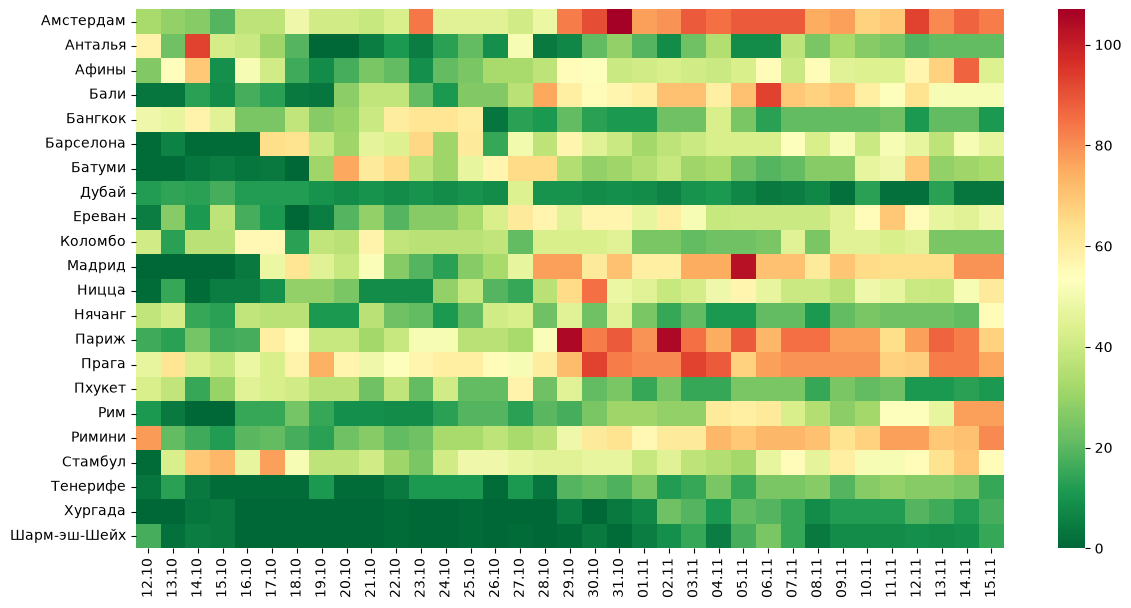

In [14]:
heat = df.pivot_table(index='city', columns='date', values='sum_rate')
heat.columns = heat.columns.strftime('%d.%m')

plt.figure(figsize=(14, 7))
sns.heatmap(heat, cmap='RdYlGn_r')
plt.xlabel('')
plt.ylabel('')
plt.show()

### Куда ехать на следующей неделе

Прогноз на ближайшие 7-10 дней более-менее надежный, дальше уже нет. Поэтому сначала смотрим только на следующую полную неделю, на нее реально можно взять отпуск и довериться прогнозу.

In [15]:
future = df[df['date'] > collected_at].copy()#прошедшие дни не берем
future['week'] = future['date'].dt.to_period('W')

weeks = (
    future.groupby(['country', 'city', 'week'])
          .agg(sum_rate=('sum_rate', 'sum'), days=('sum_rate', 'count'))
          .reset_index()
          .query('days == 7')#берем только полные недели
          .drop(columns='days')
)

next_week = weeks['week'].min()#ближайшая полная неделя
weeks[weeks['week'] == next_week].sort_values('sum_rate').head(10)

,country,city,week,sum_rate
26,Египет,Шарм-эш-Шейх,2026-10-19/2026-10-25,2
21,Египет,Хургада,2026-10-19/2026-10-25,2
46,Испания,Тенерифе,2026-10-19/2026-10-25,50
81,Турция,Анталья,2026-10-19/2026-10-25,55
66,ОАЭ,Дубай,2026-10-19/2026-10-25,64
51,Италия,Рим,2026-10-19/2026-10-25,81
11,Греция,Афины,2026-10-19/2026-10-25,126
6,Вьетнам,Нячанг,2026-10-19/2026-10-25,134
91,Франция,Ницца,2026-10-19/2026-10-25,146
1,Армения,Ереван,2026-10-19/2026-10-25,159


### Топ 10 лучших недель на месяц вперед

Теперь все так же по всем неделям, которые есть в прогнозе

In [16]:
weeks.sort_values('sum_rate').head(10)

,country,city,week,sum_rate
26,Египет,Шарм-эш-Шейх,2026-10-19/2026-10-25,2
21,Египет,Хургада,2026-10-19/2026-10-25,2
27,Египет,Шарм-эш-Шейх,2026-10-26/2026-11-01,12
22,Египет,Хургада,2026-10-26/2026-11-01,16
69,ОАЭ,Дубай,2026-11-09/2026-11-15,38
46,Испания,Тенерифе,2026-10-19/2026-10-25,50
68,ОАЭ,Дубай,2026-11-02/2026-11-08,50
81,Турция,Анталья,2026-10-19/2026-10-25,55
66,ОАЭ,Дубай,2026-10-19/2026-10-25,64
29,Египет,Шарм-эш-Шейх,2026-11-09/2026-11-15,65


## Выводы

Лучшие недели мы нашли, у меня так совпало, что следующие недели в Египте просто замечательные, причем настолько, что самому захотелось в отпуск, были бы только на это деньги)

По итогам работы, мы распарсили Гисметео, обработали полученные данные по подходящим для нас критериям, получили топ лучших надежных (ближайшие недели) и не самых надежных (прогноз на месяц вперед) недель. Теперь мы можем отталкиваться от этих данных, чтобы выбирать места и даты поездок

## Таблицы на момент запуска, 13 октября 2026

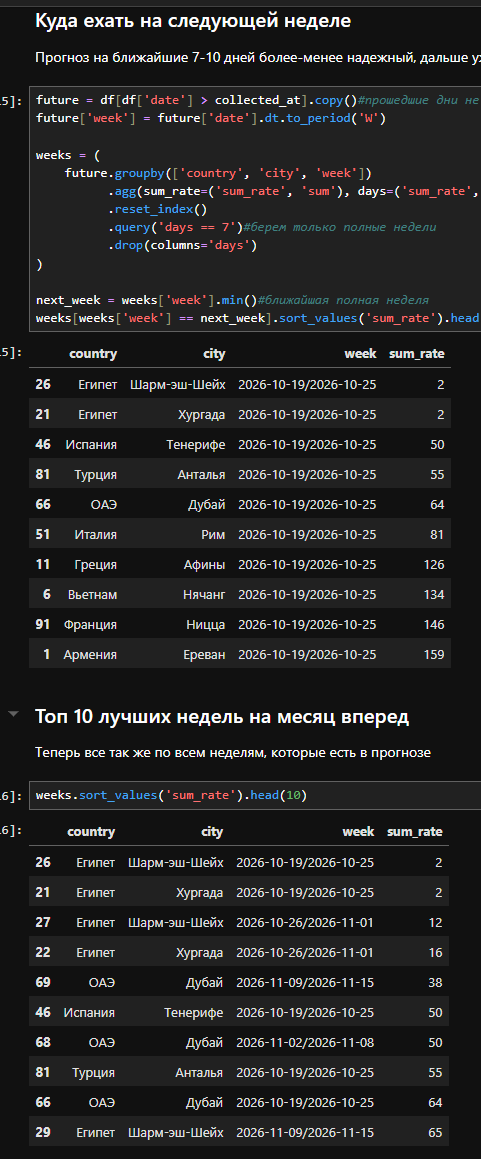